<a href="https://colab.research.google.com/github/naserhusovic-droid/dsb_capston/blob/main/Finall_01_EDA_Cleaned.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CAPSTONE PROJECT
## Irregular Migration Across the Western Balkan Route: The Case of Montenegro (2016–2026)

### Notebook 01 — Data Ingestion, Cleaning and Exploratory Data Analysis (EDA)

**Purpose:** prepare and explore the five selected sheets from the IOM DTM Europe Q1 2026 workbook.

**Important interpretation:** `Arrivals` represents recorded arrivals/events as defined by the source; it should not automatically be interpreted as a count of unique individuals. `Individuals present` is a different measure and must not be added to `Arrivals`.

The workbook contains nine sheets. This notebook loads the five selected analytical sheets only.


## 1. Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## 2. Load the five selected sheets

In [4]:
file_path = '/content/DTM Europe_Q1_2026_Dataset.xlsx'

selected_sheets = [
    'First_Arrival_Countries_Monthly',
    'Other_Countries_Areas_Monthly',
    'First_Arrival_Countries_CoO',
    'Others_Countries_CoO',
    'All_Migrant_Presence'
]

datasets = {
    sheet: pd.read_excel(file_path, sheet_name=sheet)
    for sheet in selected_sheets
}

# Short names used throughout the notebook
im1_1 = datasets['First_Arrival_Countries_Monthly']
im1_2 = datasets['Other_Countries_Areas_Monthly']
im1_3 = datasets['First_Arrival_Countries_CoO']
im1_4 = datasets['Others_Countries_CoO']
im1_5 = datasets['All_Migrant_Presence']

print('Loaded sheets:', list(datasets.keys()))

Loaded sheets: ['First_Arrival_Countries_Monthly', 'Other_Countries_Areas_Monthly', 'First_Arrival_Countries_CoO', 'Others_Countries_CoO', 'All_Migrant_Presence']


## 3. Inspect dataset structure

In [5]:
for name, data in datasets.items():
    print(f'\\n{"=" * 60}')
    print(f'DATASET: {name}')
    print('Shape:', data.shape)
    print('Columns:', data.columns.tolist())
    print('Data types:')
    print(data.dtypes)
    print('First rows:')
    display(data.head(3))

\n============================================================
DATASET: First_Arrival_Countries_Monthly
Shape: (1128, 7)
Columns: ['Date', 'Year', 'Month', 'ISO3 - Country of arrival', 'Route', 'Type of arrival', 'Arrivals']
Data types:
Date                         datetime64[ns]
Year                                  int64
Month                                 int64
ISO3 - Country of arrival            object
Route                                object
Type of arrival                      object
Arrivals                              int64
dtype: object
First rows:


,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
0,2016-01-31,2016,1,BGR,EMR,Land,596
1,2017-01-31,2017,1,BGR,EMR,Land,48
2,2018-01-31,2018,1,BGR,EMR,Land,116


\n============================================================
DATASET: Other_Countries_Areas_Monthly
Shape: (1066, 7)
Columns: ['Date', 'Year', 'Month', 'ISO3 - Country of arrival', 'Route', 'Type of arrival', 'Arrivals']
Data types:
Date                         datetime64[ns]
Year                                  int64
Month                                 int64
ISO3 - Country of arrival            object
Route                                object
Type of arrival                      object
Arrivals                              int64
dtype: object
First rows:


,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
0,2016-01-31,2016,1,ALB,WBR,Land,55
1,2017-01-31,2017,1,ALB,WBR,Land,108
2,2018-01-31,2018,1,ALB,WBR,Land,114


\n============================================================
DATASET: First_Arrival_Countries_CoO
Shape: (330, 8)
Columns: ['Date', 'Year', 'Month', 'ISO3 - Country of origin', 'ISO3 - Country of arrival', 'Route', 'Arrivals', 'Source']
Data types:
Date                         datetime64[ns]
Year                                  int64
Month                                 int64
ISO3 - Country of origin             object
ISO3 - Country of arrival            object
Route                                object
Arrivals                              int64
Source                               object
dtype: object
First rows:


,Date,Year,Month,ISO3 - Country of origin,ISO3 - Country of arrival,Route,Arrivals,Source
0,2026-01-31,2026,1,SLE,MLT,CMR,1,"Maltese Minitry of Home Affairs, Security and ..."
1,2026-01-31,2026,1,BFA,ITA,CMR,2,Italian Ministry of the Interior
2,2026-01-31,2026,1,BGD,ITA,CMR,497,Italian Ministry of the Interior


\n============================================================
DATASET: Others_Countries_CoO
Shape: (439, 8)
Columns: ['Date', 'Year', 'Month', 'ISO3 - Country of origin', 'ISO3 - Country of arrival', 'Route', 'Arrivals', 'Source']
Data types:
Date                         datetime64[ns]
Year                                  int64
Month                                 int64
ISO3 - Country of origin             object
ISO3 - Country of arrival            object
Route                                object
Arrivals                              int64
Source                               object
dtype: object
First rows:


,Date,Year,Month,ISO3 - Country of origin,ISO3 - Country of arrival,Route,Arrivals,Source
0,2026-01-31,2026,1,AFG,XKX,WBR,1,"Kosovo* Ministry of Internal Affairs, Border P..."
1,2026-01-31,2026,1,DZA,XKX,WBR,21,"Kosovo* Ministry of Internal Affairs, Border P..."
2,2026-01-31,2026,1,EGY,XKX,WBR,15,"Kosovo* Ministry of Internal Affairs, Border P..."


\n============================================================
DATASET: All_Migrant_Presence
Shape: (147, 6)
Columns: ['Date', 'Year', 'Month', 'Week', 'ISO3 - Host country', 'Individuals present']
Data types:
Date                   datetime64[ns]
Year                            int64
Month                           int64
Week                            int64
ISO3 - Host country            object
Individuals present             int64
dtype: object
First rows:


,Date,Year,Month,Week,ISO3 - Host country,Individuals present
0,2026-01-04,2026,1,2,ALB,5
1,2026-01-11,2026,1,3,ALB,5
2,2026-01-18,2026,1,4,ALB,5


## 4. Check missing values and duplicate rows

In [6]:
quality_report = []

for name, data in datasets.items():
    quality_report.append({
        'Dataset': name,
        'Rows': len(data),
        'Columns': data.shape[1],
        'Duplicate rows': int(data.duplicated().sum()),
        'Missing cells': int(data.isna().sum().sum())
    })

display(pd.DataFrame(quality_report))

for name, data in datasets.items():
    missing = pd.DataFrame({
        'Missing values': data.isna().sum(),
        'Missing percentage': (data.isna().mean() * 100).round(2)
    })
    print(f'\\n{name}')
    display(missing)

,Dataset,Rows,Columns,Duplicate rows,Missing cells
0,First_Arrival_Countries_Monthly,1128,7,0,0
1,Other_Countries_Areas_Monthly,1066,7,0,0
2,First_Arrival_Countries_CoO,330,8,0,0
3,Others_Countries_CoO,439,8,0,0
4,All_Migrant_Presence,147,6,0,0


\nFirst_Arrival_Countries_Monthly


,Missing values,Missing percentage
Date,0,0.0
Year,0,0.0
Month,0,0.0
ISO3 - Country of arrival,0,0.0
Route,0,0.0
Type of arrival,0,0.0
Arrivals,0,0.0


\nOther_Countries_Areas_Monthly


,Missing values,Missing percentage
Date,0,0.0
Year,0,0.0
Month,0,0.0
ISO3 - Country of arrival,0,0.0
Route,0,0.0
Type of arrival,0,0.0
Arrivals,0,0.0


\nFirst_Arrival_Countries_CoO


,Missing values,Missing percentage
Date,0,0.0
Year,0,0.0
Month,0,0.0
ISO3 - Country of origin,0,0.0
ISO3 - Country of arrival,0,0.0
Route,0,0.0
Arrivals,0,0.0
Source,0,0.0


\nOthers_Countries_CoO


,Missing values,Missing percentage
Date,0,0.0
Year,0,0.0
Month,0,0.0
ISO3 - Country of origin,0,0.0
ISO3 - Country of arrival,0,0.0
Route,0,0.0
Arrivals,0,0.0
Source,0,0.0


\nAll_Migrant_Presence


,Missing values,Missing percentage
Date,0,0.0
Year,0,0.0
Month,0,0.0
Week,0,0.0
ISO3 - Host country,0,0.0
Individuals present,0,0.0


## 5. Prepare date and numeric columns

Convert date columns to datetime and `Arrivals` to numeric. Invalid values are converted to missing values and reported; they are not silently replaced with zero.

In [7]:
for name, data in datasets.items():
    if 'Date' in data.columns:
        data['Date'] = pd.to_datetime(data['Date'], errors='coerce')

    if 'Arrivals' in data.columns:
        data['Arrivals'] = pd.to_numeric(data['Arrivals'], errors='coerce')

    datasets[name] = data

# Refresh the short references after preparation
im1_1 = datasets['First_Arrival_Countries_Monthly']
im1_2 = datasets['Other_Countries_Areas_Monthly']
im1_3 = datasets['First_Arrival_Countries_CoO']
im1_4 = datasets['Others_Countries_CoO']
im1_5 = datasets['All_Migrant_Presence']

for name, data in datasets.items():
    if 'Date' in data.columns:
        print(name, '| invalid/missing dates:', data['Date'].isna().sum())
    if 'Arrivals' in data.columns:
        print(name, '| missing Arrivals:', data['Arrivals'].isna().sum())

First_Arrival_Countries_Monthly | invalid/missing dates: 0
First_Arrival_Countries_Monthly | missing Arrivals: 0
Other_Countries_Areas_Monthly | invalid/missing dates: 0
Other_Countries_Areas_Monthly | missing Arrivals: 0
First_Arrival_Countries_CoO | invalid/missing dates: 0
First_Arrival_Countries_CoO | missing Arrivals: 0
Others_Countries_CoO | invalid/missing dates: 0
Others_Countries_CoO | missing Arrivals: 0
All_Migrant_Presence | invalid/missing dates: 0


## 6. Check country codes and route labels

In [8]:
for name, data in datasets.items():
    print(f'\\n{name}')
    for column in data.columns:
        if column.startswith('ISO3'):
            codes = sorted(data[column].dropna().astype(str).unique())
            print(column, '| unique codes:', len(codes), '| Montenegro (MNE):', 'MNE' in codes)

print('\\nRoutes in First_Arrival_Countries_Monthly:')
print(im1_1['Route'].value_counts(dropna=False))

print('\\nRoutes in Other_Countries_Areas_Monthly:')
print(im1_2['Route'].value_counts(dropna=False))

\nFirst_Arrival_Countries_Monthly
ISO3 - Country of arrival | unique codes: 6 | Montenegro (MNE): False
\nOther_Countries_Areas_Monthly
ISO3 - Country of arrival | unique codes: 9 | Montenegro (MNE): True
\nFirst_Arrival_Countries_CoO
ISO3 - Country of origin | unique codes: 54 | Montenegro (MNE): False
ISO3 - Country of arrival | unique codes: 6 | Montenegro (MNE): False
\nOthers_Countries_CoO
ISO3 - Country of origin | unique codes: 62 | Montenegro (MNE): False
ISO3 - Country of arrival | unique codes: 8 | Montenegro (MNE): True
\nAll_Migrant_Presence
ISO3 - Host country | unique codes: 12 | Montenegro (MNE): True
\nRoutes in First_Arrival_Countries_Monthly:
Route
EMR     593
WMR     234
CMR     195
WAAR    106
Name: count, dtype: int64
\nRoutes in Other_Countries_Areas_Monthly:
Route
WBR         724
EU Other    342
Name: count, dtype: int64


## 7. Explore first-arrival routes

This sheet contains route categories such as EMR, WMR, CMR and WAAR in the notebook's inspected output. It did **not** contain Montenegro in `ISO3 - Country of arrival`, so it is not the source for the Montenegro Western Balkan Route target.

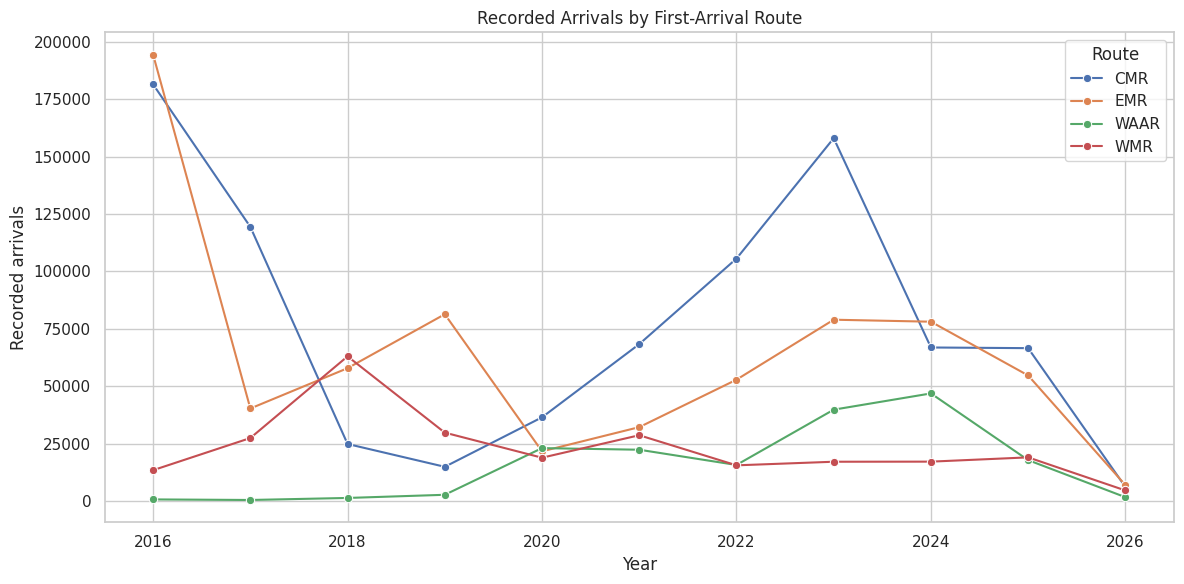

Arrival countries in im1_1:
['BGR', 'CYP', 'ESP', 'GRC', 'ITA', 'MLT']


In [9]:
route_first_arrival = (
    im1_1.groupby(['Year', 'Route'], as_index=False)['Arrivals']
    .sum()
    .sort_values('Year')
)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=route_first_arrival,
    x='Year',
    y='Arrivals',
    hue='Route',
    marker='o'
)
plt.title('Recorded Arrivals by First-Arrival Route')
plt.xlabel('Year')
plt.ylabel('Recorded arrivals')
plt.tight_layout()
plt.show()

print('Arrival countries in im1_1:')
print(sorted(im1_1['ISO3 - Country of arrival'].dropna().unique()))

## 8. Explore Other Countries/Areas and prepare the main route series

The inspected notebook output shows `WBR` and `EU Other` as route labels in this sheet. The following creates a monthly total for WBR across the countries represented in this sheet.

In [10]:
western_balkan_route_name = 'WBR'

df_wb = im1_2.copy()
df_wb = df_wb.dropna(subset=['Date', 'Arrivals'])
df_wb = df_wb[df_wb['Route'] == western_balkan_route_name].copy()

df_wb['Month_Start'] = df_wb['Date'].dt.to_period('M').dt.to_timestamp()

wb_monthly = (
    df_wb.groupby('Month_Start')['Arrivals']
    .sum()
    .sort_index()
)

display(wb_monthly.head())
display(wb_monthly.tail())
print('WBR monthly observations:', len(wb_monthly))
print('Period:', wb_monthly.index.min(), 'to', wb_monthly.index.max())

,Arrivals
Month_Start,
2016-01-01,112050
2016-02-01,70580
2016-03-01,3335
2016-04-01,99
2016-05-01,559


,Arrivals
Month_Start,
2025-11-01,3995
2025-12-01,2621
2026-01-01,1660
2026-02-01,2763
2026-03-01,3284


WBR monthly observations: 123
Period: 2016-01-01 00:00:00 to 2026-03-01 00:00:00


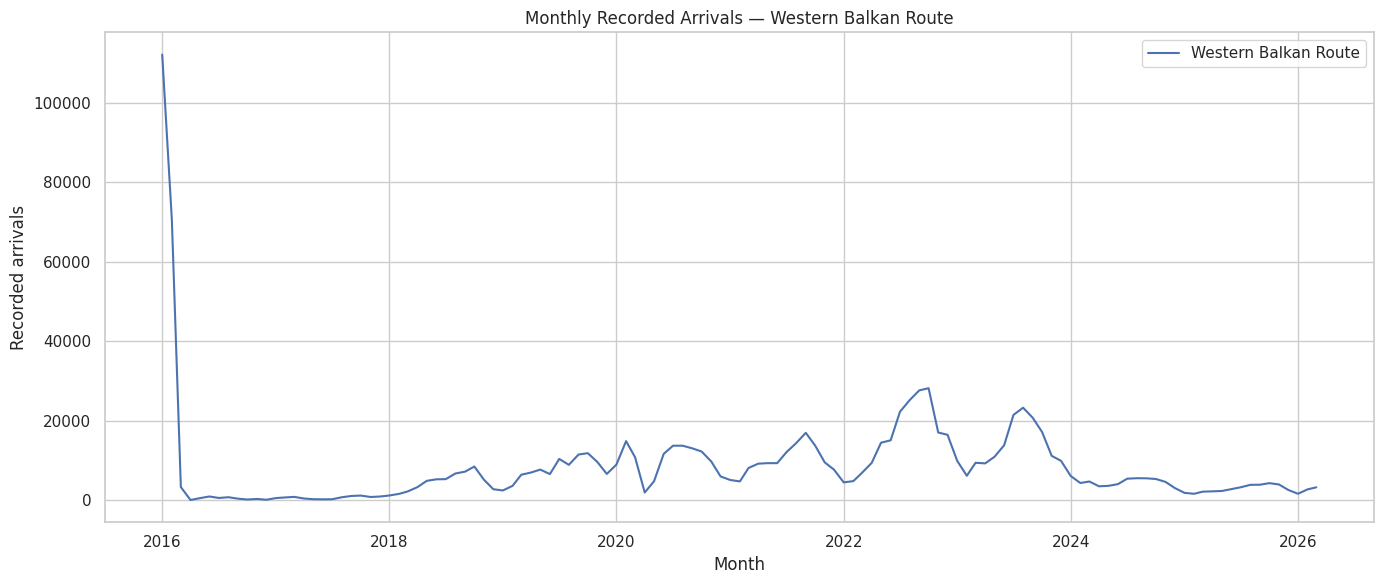

In [11]:
plt.figure(figsize=(14, 6))
plt.plot(wb_monthly.index, wb_monthly.values, label='Western Balkan Route')
plt.title('Monthly Recorded Arrivals — Western Balkan Route')
plt.xlabel('Month')
plt.ylabel('Recorded arrivals')
plt.legend()
plt.tight_layout()
plt.show()

## 9. Prepare the Montenegro Western Balkan Route series

**Important correction:** the earlier exploratory code filtered only `MNE`, so it could include records from more than one route. For a Montenegro-specific Western Balkan Route series, filter by **both** `Route == 'WBR'` and `ISO3 - Country of arrival == 'MNE'`.

In [12]:
df_mne_wbr = im1_2.copy()
df_mne_wbr = df_mne_wbr.dropna(subset=['Date', 'Arrivals'])

df_mne_wbr = df_mne_wbr[
    (df_mne_wbr['Route'] == western_balkan_route_name) &
    (df_mne_wbr['ISO3 - Country of arrival'] == 'MNE')
].copy()

df_mne_wbr['Month_Start'] = (
    df_mne_wbr['Date'].dt.to_period('M').dt.to_timestamp()
)

mne_wbr_monthly = (
    df_mne_wbr.groupby('Month_Start')['Arrivals']
    .sum()
    .sort_index()
)

display(mne_wbr_monthly.head())
display(mne_wbr_monthly.tail())
print('Montenegro WBR monthly observations:', len(mne_wbr_monthly))
print('Period:', mne_wbr_monthly.index.min(), 'to', mne_wbr_monthly.index.max())
print('Total recorded arrivals in this filtered series:', mne_wbr_monthly.sum())

,Arrivals
Month_Start,
2016-01-01,81
2016-02-01,15
2016-03-01,3
2016-04-01,9
2016-05-01,2


,Arrivals
Month_Start,
2025-11-01,364
2025-12-01,257
2026-01-01,203
2026-02-01,405
2026-03-01,453


Montenegro WBR monthly observations: 123
Period: 2016-01-01 00:00:00 to 2026-03-01 00:00:00
Total recorded arrivals in this filtered series: 40897


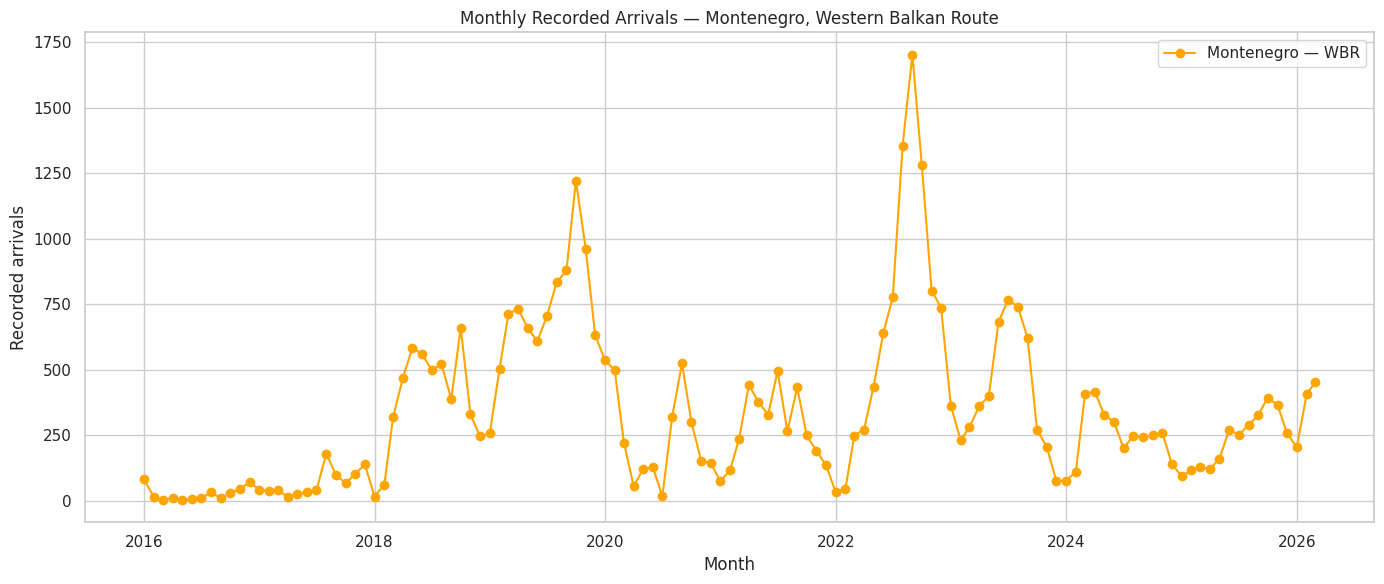

In [17]:
plt.figure(figsize=(14, 6))
plt.plot(
    mne_wbr_monthly.index,
    mne_wbr_monthly.values,
    marker='o',
    label='Montenegro — WBR',
    color='orange'
)
plt.title('Monthly Recorded Arrivals — Montenegro, Western Balkan Route')
plt.xlabel('Month')
plt.ylabel('Recorded arrivals')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Explore countries of origin

The two CoO sheets contain origin and arrival country fields. They can support a separate descriptive analysis of origin-country patterns. Before using them for a forecast, verify their date coverage, definitions and overlap with the monthly sheets. Do not add their `Arrivals` values to the monthly sheet totals.

In [14]:
print('Others_Countries_CoO date range:')
print(im1_4['Date'].min(), 'to', im1_4['Date'].max())

print('Routes in Others_Countries_CoO:')
print(im1_4['Route'].value_counts(dropna=False))

mne_origin = im1_4[
    (im1_4['Route'] == western_balkan_route_name) &
    (im1_4['ISO3 - Country of arrival'] == 'MNE')
].copy()

origin_summary = (
    mne_origin.groupby('ISO3 - Country of origin', as_index=False)['Arrivals']
    .sum()
    .sort_values('Arrivals', ascending=False)
)

display(origin_summary.head(15))

Others_Countries_CoO date range:
2026-01-31 00:00:00 to 2026-03-31 00:00:00
Routes in Others_Countries_CoO:
Route
WBR         303
EU Other    136
Name: count, dtype: int64


,ISO3 - Country of origin,Arrivals
19,SDN,696
5,EGY,171
16,PAK,31
0,AFG,29
4,DZA,17
6,ERI,13
18,RUS,12
17,PSE,11
1,BGD,11
7,IND,10


## 11. Explore migrant presence separately

`All_Migrant_Presence` uses `Individuals present`, not `Arrivals`. The inspected notebook output covers weekly observations in 2026. Keep this as a separate descriptive measure; do not combine it with monthly arrival counts.

In [15]:
mne_presence = im1_5[
    im1_5['ISO3 - Host country'] == 'MNE'
].copy()

display(mne_presence.sort_values('Date'))
print('Presence date range:', mne_presence['Date'].min(), 'to', mne_presence['Date'].max())

,Date,Year,Month,Week,ISO3 - Host country,Individuals present
87,2026-01-04,2026,1,2,MNE,79
88,2026-01-11,2026,1,3,MNE,60
89,2026-01-18,2026,1,4,MNE,54
90,2026-01-25,2026,1,5,MNE,44
91,2026-02-01,2026,1,6,MNE,51
92,2026-02-08,2026,2,7,MNE,68
93,2026-02-15,2026,2,8,MNE,62
94,2026-02-22,2026,2,9,MNE,73
95,2026-03-01,2026,2,10,MNE,46
96,2026-03-08,2026,3,11,MNE,46


Presence date range: 2026-01-04 00:00:00 to 2026-03-22 00:00:00
